# Which applicants should a lender approve, and at what cut-off?

**Reader:** head of consumer credit. **Decision:** which loan applicants to approve, and where to set the score cut-off.
**Data:** 113,937 Prosper peer-to-peer loans (2005 to 2014); 40,924 post-relaunch loans with a complete 12-month outcome window are modeled. The plan, target definition, split and predictions were written before modeling in [research_plan.md](../research_plan.md).

## Answer in brief
- **Use an explainable scorecard.** On loans it had never seen (originated Jul 2012 to Mar 2013) it ranks risk better than Prosper's own score: AUC **0.711 vs 0.647** (difference +0.064, 95% CI +0.042 to +0.083).
- **A boosted model adds little.** +0.012 AUC (CI −0.001 to +0.023), not distinguishable from zero, and it gives up reason codes.
- **Set the cut-off by cost, not accuracy.** A bad loan loses 88% of principal; a good loan earns an assumed 10%. At those assumptions the profit-maximizing cut-off approves **about 76%** of loans. Declined loans went bad **13.2%** of the time vs **3.9%** for approved. The cut-off earns **$0.39M more** than approving everyone on $104M of test-set loans (95% CI $0.18M to $0.59M), while approving 24% fewer loans (14% fewer dollars lent).
- **The assumption matters more than the model.** Across plausible margins the best approval share ranges from 30% to 96%, so the bank's own margin and loss figures should replace mine.
- **Limit:** only funded loans are observed, so this is not a complete underwriting policy (see the end).

In [1]:
import sys, warnings; sys.path.insert(0, "../src"); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.isotonic import IsotonicRegression
import credit as cr

NAVY, ORANGE, GREY = "#2f4b7c", "#e08b3a", "#8a8f98"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = "../reports/figures/"

## 1. Who is in the data, and what counts as "bad"
**Bad** = charged off or defaulted within 12 months of origination. Loans are limited to the post-July-2009 relaunch (a different rating system from earlier loans) and to those originated early enough to have had the full 12 months before the file ends on 2014-03-10.

In [2]:
raw = pd.read_csv(cr.RAW, low_memory=False)
steps = [("Rows in file", len(raw))]
d0 = raw.drop_duplicates("ListingKey"); steps.append(("One row per listing", len(d0)))
d0 = d0.assign(orig=pd.to_datetime(d0.LoanOriginationDate, format="ISO8601"))
d0 = d0[d0.LoanStatus != "Cancelled"]; steps.append(("Drop cancelled", len(d0)))
d0 = d0[d0.orig >= cr.RELAUNCH]; steps.append(("Originated after the July 2009 relaunch", len(d0)))
cut = cr.DATA_END - pd.DateOffset(months=12)
d0 = d0[d0.orig <= cut]; steps.append((f"Full 12-month window (originated by {cut.date()})", len(d0)))
pd.DataFrame(steps, columns=["step", "loans"]).set_index("step")

,loans
step,
Rows in file,113937
One row per listing,113066
Drop cancelled,113061
Originated after the July 2009 relaunch,84113
Full 12-month window (originated by 2013-03-10),40924


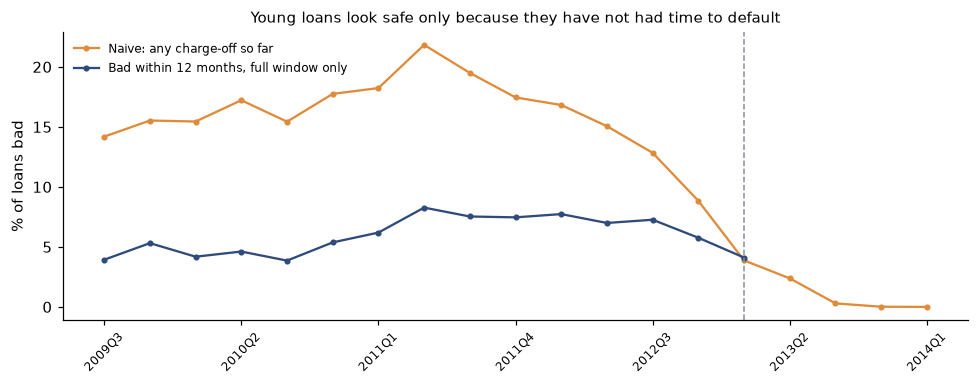

orig,2012Q3,2012Q4,2013Q1,2013Q2,2013Q3,2013Q4,2014Q1
naive bad rate,0.128,0.088,0.039,0.024,0.003,0.0,0.0


In [3]:
# Why censoring matters: label by status alone, with no window, and recent vintages look safe only because they are young.
p = raw.drop_duplicates("ListingKey").assign(orig=lambda x: pd.to_datetime(x.LoanOriginationDate, format="ISO8601"))
p = p[(p.orig >= cr.RELAUNCH) & (p.LoanStatus != "Cancelled")]
p["naive_bad"] = p.LoanStatus.isin(["Chargedoff", "Defaulted"]).astype(int)
q = p.groupby(p.orig.dt.to_period("Q")).naive_bad.mean()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(q.index.astype(str), 100 * q.values, color=ORANGE, marker="o", ms=3, label="Naive: any charge-off so far")
d = cr.load_cohort()
q2 = d.groupby(d.LoanOriginationDate.dt.to_period("Q")).bad.mean()
ax.plot(q2.index.astype(str), 100 * q2.values, color=NAVY, marker="o", ms=3, label="Bad within 12 months, full window only")
ax.axvline(str(pd.Period(cut, "Q")), color=GREY, ls="--", lw=1)
ax.set_xticks(range(0, len(q), 3), q.index.astype(str)[::3], rotation=45, fontsize=8)
ax.set_ylabel("% of loans bad"); ax.legend(frameon=False, fontsize=8); ax.set_title("Young loans look safe only because they have not had time to default", fontsize=10)
plt.tight_layout(); plt.savefig(FIG + "censoring.png"); plt.show()
q.round(3).tail(7).to_frame("naive bad rate").T

**Why the window matters.** The orange line labels a loan bad if it has been charged off *at any point so far*. It falls to almost zero for loans from late 2013, but only because those loans are months old and have not had time to default; counting them as "good" would make recent applicants look far safer than they are. (The orange line also sits above the blue one for older vintages because it includes defaults after month 12.) The blue line uses an identical 12-month window for every loan and is comparable across time, so loans originated after 2013-03-10 are excluded.

## 2. Time-based split and the cost of a bad loan
Models are fit on the oldest loans, tuned on the next, and scored once on the newest. A random split would let the model see the future of the same vintages.

In [4]:
tr, va, te = [d[d.split == s] for s in ["train", "valid", "test"]]
print(d.groupby("split").agg(loans=("bad", "size"), bad_rate=("bad", "mean"), first=("LoanOriginationDate", "min"), last=("LoanOriginationDate", "max")).loc[["train", "valid", "test"]].round(4).to_string())
lgd = cr.loss_given_default(tr)
print(f"\nLoss given default (net principal loss / original amount, bad loans in train): {lgd:.1%}")

       loans  bad_rate      first       last
split                                       
train  18914    0.0632 2009-07-20 2011-12-30
valid   9496    0.0734 2012-01-03 2012-06-29
test   12514    0.0611 2012-07-02 2013-03-08

Loss given default (net principal loss / original amount, bad loans in train): 87.8%


Bad rates are 6.3% (train), 7.3% (validation) and 6.1% (test). A bad loan loses **88% of principal on average** (measured on training loans, net of recoveries). If a good loan earns 10%, one bad loan wipes out the profit of about nine good ones. That asymmetry is why the cut-off is chosen by cost.

## 3. Leakage warning
Fields recorded after origination (principal loss, days delinquent, months on book) are excluded from every model. For scale, a model allowed to see them:

In [5]:
feats = cr.NUMERIC + cr.CATEGORICAL
leaky = ["LP_GrossPrincipalLoss", "LP_NetPrincipalLoss", "LoanCurrentDaysDelinquent", "LoanMonthsSinceOrigination"]
Xl = lambda x: x[cr.NUMERIC + leaky].fillna(-1)
from sklearn.ensemble import HistGradientBoostingClassifier
gl = HistGradientBoostingClassifier(max_depth=3, max_iter=100, random_state=0).fit(Xl(tr), tr.bad)
print(f"AUC on test WITH post-origination fields: {roc_auc_score(te.bad, gl.predict_proba(Xl(te))[:, 1]):.3f}  <- impossible in real underwriting")

AUC on test WITH post-origination fields: 0.992  <- impossible in real underwriting


AUC 0.99 is not skill; it is the model reading the outcome. Real underwriting only has information available at application.

## 4. Models: scorecard, boosted model, and Prosper's own score
The **scorecard** bins each variable by weight of evidence and fits a logistic regression, then converts the result to points (+40 points doubles the good/bad odds). The **boosted model** uses the same inputs. **Prosper's own score** is the benchmark the platform already had.

In [6]:
sc = cr.Scorecard(cr.NUMERIC, cr.CATEGORICAL).fit(tr[feats], tr.bad)
gbm, levels = cr.fit_gbm(tr, tr.bad)
pred = {}
for name, x in [("valid", va), ("test", te)]:
    pred[name] = {"Scorecard": sc.predict_proba_bad(x[feats]),
                  "Boosted model": gbm.predict_proba(cr.gbm_matrix(x, levels))[:, 1],
                  "Prosper score (benchmark)": None}
rows = []
for name, x in [("valid", va), ("test", te)]:
    for m in ["Scorecard", "Boosted model"]:
        r = cr.evaluate(x.bad, pred[name][m]); rows.append(dict(set=name, model=m, **r))
    b = -x[cr.BENCHMARK].fillna(x[cr.BENCHMARK].median())
    rows.append(dict(set=name, model="Prosper score (benchmark)", auc=roc_auc_score(x.bad, b), ks=cr.ks(x.bad, b)))
res = pd.DataFrame(rows).set_index(["set", "model"]); res[["auc", "ks", "brier", "mean_pred", "actual"]].round(4)

auc      ks   brier  mean_pred  actual
set   model                                                               
valid Scorecard                  0.6973  0.2901  0.0657     0.0744  0.0734
      Boosted model              0.7162  0.3300  0.0648     0.0774  0.0734
      Prosper score (benchmark)  0.6667  0.2458     NaN        NaN     NaN
test  Scorecard                  0.7108  0.3203  0.0552     0.0668  0.0611
      Boosted model              0.7225  0.3494  0.0550     0.0701  0.0611
      Prosper score (benchmark)  0.6469  0.2352     NaN        NaN     NaN

In [7]:
iv = pd.Series(sc.binner.iv).sort_values(ascending=False)
print("Information value (top 12; > 0.1 is a useful predictor):"); print(iv.head(12).round(3).to_string())
print(f"\nFeatures kept (IV >= 0.02): {len(sc.cols)} of {len(feats)}")

Information value (top 12; > 0.1 is a useful predictor):
ScorexChangeAtTimeOfListing    0.139
StatedMonthlyIncome            0.139
CreditScoreRangeLower          0.133
IncomeRange                    0.125
OnTimeProsperPayments          0.112
EmploymentStatus               0.097
LoanOriginalAmount             0.086
InquiriesLast6Months           0.082
DebtToIncomeRatio              0.082
OpenCreditLines                0.079
TradesOpenedLast6Months        0.076
CurrentCreditLines             0.073

Features kept (IV >= 0.02): 28 of 39


In [8]:
# Points table for the three strongest drivers: how many points each bin adds or removes
coef = dict(zip(sc.cols, sc.lr.coef_[0]))
rows = []
for f in iv.index[:3]:
    for b, w in sc.binner.woe[f].items():
        rows.append(dict(feature=f, bin=sc.binner.bin_label(f, b), order=(-1 if b == "missing" else int(b) if f in sc.binner.edges else 0), points=-sc.factor * coef.get(f, 0) * w))
pts = pd.DataFrame(rows)
pts["points"] = pts.points.round(1); pts.sort_values(["feature", "order"]).set_index(["feature", "bin"])[["points"]]

points
feature                     bin                   
CreditScoreRangeLower       (min, 640]       -13.4
                            (640, 660]       -10.8
                            (660, 680]        -0.7
                            (680, 700]        -5.0
                            (700, 720]         7.4
                            (720, 740]         9.4
                            (740, 780]        17.4
                            (780, max]        42.8
ScorexChangeAtTimeOfListing missing           -5.6
                            (min, -48]       -13.4
                            (-48, -26]         7.1
                            (-26, -11]        12.7
                            (-11, 2]          15.5
                            (2, 16]           26.0
                            (16, 35]          25.2
                            (35, 66.38]       33.2
                            (66.38, max]      22.3
StatedMonthlyIncome         (min, 2,309]     -10.1
                            (2,309, 3,098]    -7.1
                            (3,098, 3,803]    -2.9
                            (3,803, 4,583]     0.3
                            (4,583, 5,417]     1.6
                            (5,417, 6,667]     3.7
                            (6,667, 8,667]     9.9
                            (8,667, max]      14.7

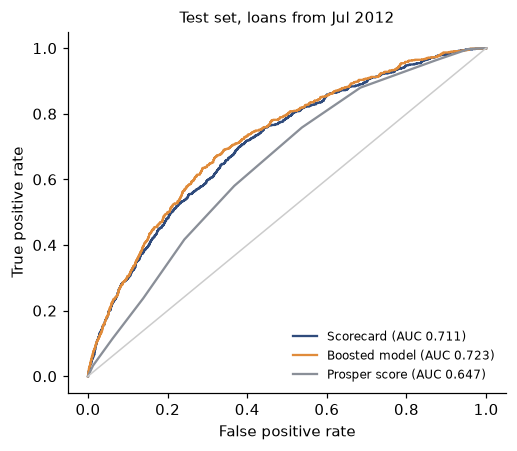

In [9]:
fig, ax = plt.subplots(figsize=(4.8, 4.2))
for m, col in [("Scorecard", NAVY), ("Boosted model", ORANGE)]:
    fpr, tpr, _ = roc_curve(te.bad, pred["test"][m]); ax.plot(fpr, tpr, color=col, label=f"{m} (AUC {roc_auc_score(te.bad, pred['test'][m]):.3f})")
b = -te[cr.BENCHMARK].fillna(te[cr.BENCHMARK].median()); fpr, tpr, _ = roc_curve(te.bad, b)
ax.plot(fpr, tpr, color=GREY, label=f"Prosper score (AUC {roc_auc_score(te.bad, b):.3f})"); ax.plot([0, 1], [0, 1], color="#ccc", lw=1)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.legend(frameon=False, fontsize=8, loc="lower right"); ax.set_title("Test set, loans from Jul 2012", fontsize=10)
plt.tight_layout(); plt.savefig(FIG + "roc.png"); plt.show()

In [10]:
# Is the boosted model's edge real? Bootstrap the test set (paired, so both models see the same resample).
rng = np.random.default_rng(0)
yb, ps_, pg_ = te.bad.values, pred["test"]["Scorecard"], pred["test"]["Boosted model"]
bm = -te[cr.BENCHMARK].fillna(te[cr.BENCHMARK].median()).values
idx = [rng.integers(0, len(yb), len(yb)) for _ in range(500)]
a_s = np.array([roc_auc_score(yb[i], ps_[i]) for i in idx]); a_g = np.array([roc_auc_score(yb[i], pg_[i]) for i in idx]); a_b = np.array([roc_auc_score(yb[i], bm[i]) for i in idx])
ci = lambda x: f"[{np.percentile(x, 2.5):.3f}, {np.percentile(x, 97.5):.3f}]"
print(f"Test AUC 95% CI  scorecard {ci(a_s)} | boosted {ci(a_g)} | Prosper score {ci(a_b)}")
print(f"Boosted minus scorecard: {np.mean(a_g - a_s):+.3f} {ci(a_g - a_s)}")
print(f"Scorecard minus Prosper score: {np.mean(a_s - a_b):+.3f} {ci(a_s - a_b)}")

Test AUC 95% CI  scorecard [0.692, 0.727] | boosted [0.702, 0.740] | Prosper score [0.628, 0.665]
Boosted minus scorecard: +0.012 [-0.001, 0.023]
Scorecard minus Prosper score: +0.064 [0.042, 0.083]


In [11]:
# Reason codes: the features pulling a declined applicant's score down most (what an adverse-action notice needs)
declined = va.assign(pts=sc.score(va[feats])).nsmallest(3, "pts")
rc = sc.reason_codes(declined[feats])
pd.DataFrame({"score": declined.pts.round(0), "top_reasons": rc.apply(", ".join)})

,score,top_reasons
22580,418.0,"IncomeVerifiable, OpenCreditLines, TotalTrades"
9119,432.0,"BankcardUtilization, OpenCreditLines, AmountDe..."
15893,437.0,"BankcardUtilization, IncomeVerifiable, AmountD..."


- The strongest drivers are the change in credit score at listing, stated income, credit score, income range and prior on-time Prosper payments. Credit score alone spans about 56 points between its lowest and highest bins.
- On the test set the **scorecard (AUC 0.711) clearly beats Prosper's score (0.647)**: the paired bootstrap interval for the difference is +0.042 to +0.083.
- The **boosted model (0.723) is ahead by 0.012, but the interval (−0.001 to +0.023) includes zero.** With no demonstrable gain, I recommend the scorecard: it is auditable, and the reason codes above are what a decline letter needs. The boosted model stays as a challenger to monitor.

## 5. Calibration: are the predicted probabilities right?
The cut-off depends on probabilities, not just rankings, so calibration matters.

In [12]:
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(pred["valid"]["Boosted model"], va.bad)
pred["test"]["Boosted model (recalibrated)"] = iso.predict(pred["test"]["Boosted model"])
iso_s = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(pred["valid"]["Scorecard"], va.bad)
pred["test"]["Scorecard (recalibrated)"] = iso_s.predict(pred["test"]["Scorecard"])
cal = pd.DataFrame({m: cr.evaluate(te.bad, pred["test"][m]) for m in ["Scorecard", "Scorecard (recalibrated)", "Boosted model", "Boosted model (recalibrated)"]}).T
cal[["auc", "brier", "mean_pred", "actual"]].round(4)

,auc,brier,mean_pred,actual
Scorecard,0.7108,0.0552,0.0668,0.0611
Scorecard (recalibrated),0.7096,0.0553,0.0659,0.0611
Boosted model,0.7225,0.0550,0.0701,0.0611
Boosted model (recalibrated),0.7209,0.0552,0.0671,0.0611


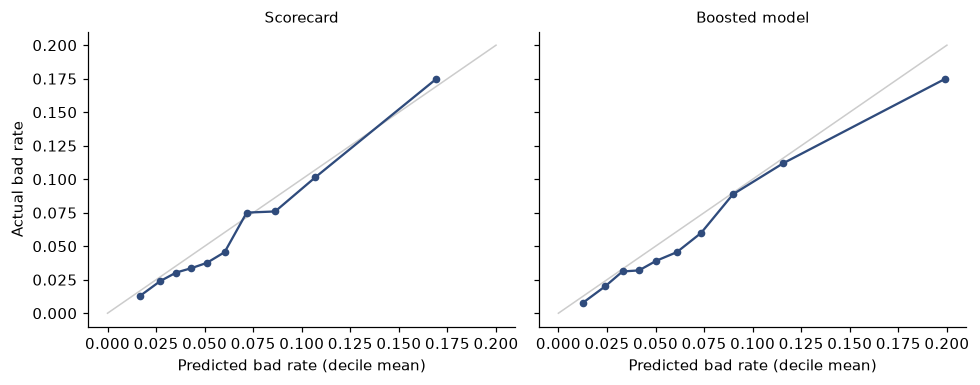

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, m in zip(axes, ["Scorecard", "Boosted model"]):
    t = cr.calibration_table(te.bad, pred["test"][m])
    ax.plot([0, 0.2], [0, 0.2], color="#ccc", lw=1); ax.plot(t.predicted, t.actual, marker="o", color=NAVY, ms=4)
    ax.set_title(m, fontsize=10); ax.set_xlabel("Predicted bad rate (decile mean)")
axes[0].set_ylabel("Actual bad rate"); plt.tight_layout(); plt.savefig(FIG + "calibration.png"); plt.show()

Both models follow the diagonal, but they run high: the scorecard predicts a 6.7% bad rate vs 6.1% actual (9% too high) and the boosted model 7.0% (15% too high; it also over-predicts the riskiest decile, 20% vs 17.5%). Recalibrating on the validation set barely helps (6.6% and 6.7%), because the problem is drift, not the shape of the model: the bad rate fell from 7.3% in validation to 6.1% in test, while the model was fit on a period averaging 6.3%. Ranking quality is unchanged by recalibration.

## 6. Stability across vintages
Population stability index (PSI): under 0.10 is stable, over 0.25 is a material shift.

In [14]:
psi_rows = [("score", cr.psi(sc.score(tr[feats]), sc.score(va[feats])), cr.psi(sc.score(tr[feats]), sc.score(te[feats])))]
for f in ["CreditScoreRangeLower", "StatedMonthlyIncome", "DebtToIncomeRatio", "LoanOriginalAmount", "InquiriesLast6Months"]:
    a_, v_, t_ = tr[f].dropna(), va[f].dropna(), te[f].dropna()
    psi_rows.append((f, cr.psi(a_, v_), cr.psi(a_, t_)))
print(d.groupby("split").LoanOriginalAmount.agg(["mean", "median"]).loc[["train", "valid", "test"]].round(0).T.to_string(), "\n")
pd.DataFrame(psi_rows, columns=["variable", "PSI train->valid", "PSI train->test"]).set_index("variable").round(3)

split    train   valid    test
mean    5867.0  7485.0  8331.0
median  5000.0  5000.0  6000.0 



,PSI train->valid,PSI train->test
variable,,
score,0.081,0.050
CreditScoreRangeLower,0.031,0.047
StatedMonthlyIncome,0.003,0.011
DebtToIncomeRatio,0.011,0.029
LoanOriginalAmount,0.924,0.967
InquiriesLast6Months,0.007,0.001


In [15]:
te = te.assign(q=te.LoanOriginationDate.dt.to_period("Q").astype(str), p=pred["test"]["Scorecard"], pg=pred["test"]["Boosted model"])
v = te.groupby("q").apply(lambda g: pd.Series({"loans": len(g), "actual_bad": g.bad.mean(), "pred_scorecard": g.p.mean(), "pred_boosted": g.pg.mean(),
                                                 "auc_scorecard": roc_auc_score(g.bad, g.p), "auc_boosted": roc_auc_score(g.bad, g.pg)}))
v.round(3)

,loans,actual_bad,pred_scorecard,pred_boosted,auc_scorecard,auc_boosted
q,,,,,,
2012Q3,5632.0,0.073,0.071,0.075,0.708,0.724
2012Q4,4425.0,0.058,0.067,0.070,0.719,0.725
2013Q1,2457.0,0.041,0.057,0.059,0.663,0.677


- The score distribution is stable (PSI 0.08 and 0.05) and so are the main credit inputs. **Loan size is the exception:** the mean loan grew from $5,900 (train) to $8,300 (test), PSI above 0.9. Dropping that feature changes test AUC only from 0.711 to 0.708, so ranking does not depend on it, but a monitoring report should flag it.
- By quarter, AUC is steady at 0.71 to 0.72 for the first two test quarters and lower (0.66) in the last, which has only 2,457 loans and about 100 bad loans, so it is noisy. In that quarter the actual bad rate (4.1%) is well below the predicted (5.7%). This data cannot say whether that is a real improvement or a one-quarter fluke.

## 7. Choosing the cut-off by cost
Profit per $1 approved = P(good) × gain − P(bad) × loss. **Loss given default is measured (88%). The gain on a good loan, 10% of principal over the horizon net of funding cost, is my assumption.** For each model, the approval share that maximizes profit is chosen on the validation set and then applied, unchanged, to the test set.

In [16]:
GAIN = 0.10
amt = va.LoanOriginalAmount.values
curves = {}
for m in ["Scorecard", "Boosted model"]:
    curves[m] = cr.profit_curve(pred["valid"][m], va.bad.values, amt, GAIN, lgd)
curves["Prosper score"] = cr.profit_curve((-va[cr.BENCHMARK].fillna(va[cr.BENCHMARK].median())).values, va.bad.values, amt, GAIN, lgd)
best = {m: c.loc[c.profit.idxmax()] for m, c in curves.items()}
print("Validation: approval share that maximizes profit (gain 10%%, loss given default %.0f%%)" % (100 * lgd))
for m, r in best.items(): print(f"  {m:14s} approve {r.approve_share:.0%}  bad rate {r.bad_rate:.1%}  profit per $ lent {r.profit_per_dollar:+.3f}")

Validation: approval share that maximizes profit (gain 10%, loss given default 88%)
  Scorecard      approve 70%  bad rate 4.6%  profit per $ lent +0.056
  Boosted model  approve 74%  bad rate 4.7%  profit per $ lent +0.060
  Prosper score  approve 92%  bad rate 6.5%  profit per $ lent +0.045


In [17]:
# Apply each model's validation-chosen approval share to the untouched test set.
amt_te, y_te = te.LoanOriginalAmount.values, te.bad.values
def pnl(mask, gain=GAIN, loss=lgd):
    a = amt_te[mask]; y = y_te[mask]; return (a * np.where(y == 1, -loss, gain)).sum(), a.sum()
risk_test = {"Scorecard": pred["test"]["Scorecard"], "Boosted model": pred["test"]["Boosted model"],
             "Prosper score": (-te[cr.BENCHMARK].fillna(te[cr.BENCHMARK].median())).values}
risk_valid = {"Scorecard": pred["valid"]["Scorecard"], "Boosted model": pred["valid"]["Boosted model"],
              "Prosper score": (-va[cr.BENCHMARK].fillna(va[cr.BENCHMARK].median())).values}
profit_all, lent_all = pnl(np.ones(len(te), bool))
rows = [dict(policy="Approve everyone", approval=1.0, bad_rate=te.bad.mean(), profit_musd=profit_all / 1e6, profit_per_dollar=profit_all / lent_all)]
masks = {}
for m in risk_test:
    thr_m = np.quantile(risk_valid[m], best[m].approve_share)      # risk threshold from validation
    masks[m] = risk_test[m] <= thr_m
    pr, ln = pnl(masks[m])
    rows.append(dict(policy=f"{m} cut-off", approval=masks[m].mean(), bad_rate=te.bad[masks[m]].mean(), profit_musd=pr / 1e6, profit_per_dollar=pr / ln))
tab = pd.DataFrame(rows).set_index("policy"); tab.round(3)

,approval,bad_rate,profit_musd,profit_per_dollar
policy,,,,
Approve everyone,1.000,0.061,5.468,0.052
Scorecard cut-off,0.759,0.039,5.859,0.065
Boosted model cut-off,0.792,0.040,5.874,0.067
Prosper score cut-off,0.935,0.058,5.532,0.055


In [18]:
sc_thr = np.quantile(sc.score(va[feats]), 1 - best["Scorecard"].approve_share)
print(f"Scorecard cut-off: approve if score >= {sc_thr:.0f} points; declined group has {te.bad[~masks['Scorecard']].mean():.1%} bad rate vs {te.bad[masks['Scorecard']].mean():.1%} approved ({(~masks['Scorecard']).sum():,} loans)")
rng = np.random.default_rng(1)
diffs = []
for _ in range(1000):
    i = rng.integers(0, len(te), len(te)); y_, a_ = y_te[i], amt_te[i]; m_ = masks["Scorecard"][i]
    pl = a_ * np.where(y_ == 1, -lgd, GAIN)
    diffs.append((pl[m_].sum() - pl.sum()) / 1e6)
print(f"Profit gain of scorecard cut-off vs approving everyone: ${np.mean(diffs):.2f}M, 95% CI [{np.percentile(diffs, 2.5):.2f}, {np.percentile(diffs, 97.5):.2f}] (test set)")

Scorecard cut-off: approve if score >= 562 points; declined group has 13.2% bad rate vs 3.9% approved (3,010 loans)

Profit gain of scorecard cut-off vs approving everyone: $0.39M, 95% CI [0.18, 0.59] (test set)


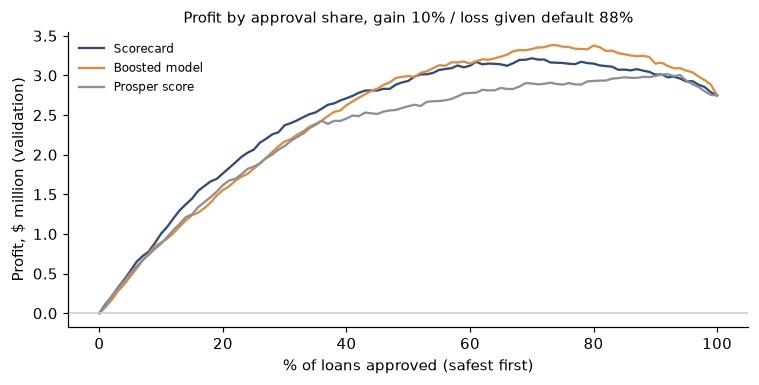

In [19]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for m, col in [("Scorecard", NAVY), ("Boosted model", ORANGE), ("Prosper score", GREY)]:
    c = curves[m]; ax.plot(100 * c.approve_share, c.profit / 1e6, color=col, label=m)
ax.axhline(0, color="#ccc", lw=1); ax.set_xlabel("% of loans approved (safest first)"); ax.set_ylabel("Profit, $ million (validation)")
ax.legend(frameon=False, fontsize=8); ax.set_title("Profit by approval share, gain 10%% / loss given default %.0f%%" % (100 * lgd), fontsize=10)
plt.tight_layout(); plt.savefig(FIG + "profit_curve.png"); plt.show()

In [20]:
# Sensitivity: how does the best approval share move with the assumptions? (validation set, scorecard)
gains, losses = [0.05, 0.10, 0.15], [lgd - 0.2, lgd, 1.0]
grid = pd.DataFrame([[cr.profit_curve(pred["valid"]["Scorecard"], va.bad.values, amt, g_, l_).pipe(lambda c: c.loc[c.profit.idxmax(), "approve_share"]) for l_ in losses] for g_ in gains],
                    index=[f"gain {g_:.0%}" for g_ in gains], columns=[f"loss {l_:.0%}" for l_ in losses])
(100 * grid).round(0).astype(int).astype(str) + "% approved"

,loss 68%,loss 88%,loss 100%
gain 5%,52% approved,30% approved,30% approved
gain 10%,87% approved,70% approved,61% approved
gain 15%,96% approved,93% approved,87% approved


- On validation the profit-maximizing share is about 70% for the scorecard and 74% for the boosted model; ranking by Prosper's own score approves 92% because it separates risk less well.
- On the untouched test set the scorecard cut-off (approve at 562 points or more) approves 76%, lowers the bad rate from 6.1% to 3.9%, and raises profit per dollar lent from 5.2 to 6.5 cents. The declined loans went bad 13.2% of the time. The total gain of **$0.39M (95% CI $0.18M to $0.59M)** comes while approving 24% fewer loans (14% fewer dollars lent).
- The boosted model earns about the same ($5.87M vs $5.86M), consistent with the earlier finding that it adds little. Prosper's score earns least ($5.53M).
- **The profit curve is a broad plateau.** On validation, profit is within a few percent of its maximum anywhere from roughly 60% to 85% approval, so the exact cut-off matters less than declining the riskiest quarter or so of applicants.
- **The sensitivity table is the main caveat.** If a good loan earns only 5%, the best policy approves just 30%; at 15% it approves 93%. The bank's true margin and loss figures should replace mine before the cut-off is used.

## 8. Robustness: a longer outcome window
Same analysis with "bad within 18 months", which shortens the data (loans must be originated by 2012-09-10).

In [21]:
d18 = cr.load_cohort(horizon_months=18)
t18, e18 = d18[d18.split == "train"], d18[d18.split == "test"]
sc18 = cr.Scorecard(cr.NUMERIC, cr.CATEGORICAL).fit(t18[feats], t18.bad)
same = te[te.LoanOriginationDate <= e18.LoanOriginationDate.max()]
print(f"18-month window: {len(d18):,} loans, bad rate {d18.bad.mean():.1%}; its test window ends {e18.LoanOriginationDate.max().date()} ({len(e18):,} loans)")
drop_amt = [c for c in cr.NUMERIC if c != "LoanOriginalAmount"]
sc_na = cr.Scorecard(drop_amt, cr.CATEGORICAL).fit(tr[drop_amt + cr.CATEGORICAL], tr.bad)
print(f"Scorecard test AUC without loan amount (a feature that drifted): {roc_auc_score(te.bad, sc_na.predict_proba_bad(te[drop_amt + cr.CATEGORICAL])):.3f} vs {res.loc[('test', 'Scorecard'), 'auc']:.3f} with it")
print(f"Scorecard AUC on that same test window: 18-month label {roc_auc_score(e18.bad, sc18.predict_proba_bad(e18[feats])):.3f} | 12-month label {roc_auc_score(same.bad, sc.predict_proba_bad(same[feats])):.3f}")

18-month window: 32,583 loans, bad rate 11.5%; its test window ends 2012-09-10 (4,173 loans)


Scorecard test AUC without loan amount (a feature that drifted): 0.708 vs 0.711 with it
Scorecard AUC on that same test window: 18-month label 0.675 | 12-month label 0.710


On the same test loans the scorecard ranks 12-month defaults better (AUC 0.710) than 18-month defaults (0.675): early defaults are easier to predict from application data than later ones. The 12-month horizon is therefore a statement about early default, and a lender concerned with lifetime losses would need a longer-horizon model.

In [22]:
# Persist test-set scores for the Streamlit cut-off simulator
out = te[["LoanOriginalAmount", "bad", "q"]].rename(columns={"LoanOriginalAmount": "amount", "q": "quarter"}).copy()
out["points"] = sc.score(te[feats]).round(1)
out["p_bad"] = pred["test"]["Scorecard (recalibrated)"].round(5)
import os; os.makedirs("../data/processed", exist_ok=True)
out.to_csv("../data/processed/test_scores.csv", index=False)
pd.Series({"lgd": lgd, "train_start": str(tr.LoanOriginationDate.min().date())}).to_json("../data/processed/params.json")
out.shape

(12514, 5)

## Findings
1. **Censoring changes the answer.** Counting young loans as good makes 2013 vintages look almost risk-free; a fixed 12-month window with complete-window loans only gives comparable bad rates (4% to 8%).
2. **The scorecard beats the platform's own score** (AUC 0.711 vs 0.647, difference +0.064, CI +0.042 to +0.083), and a boosted model adds no demonstrable gain (+0.012, CI −0.001 to +0.023).
3. **The cut-off should be set by cost.** At a measured 88% loss and an assumed 10% gain, approving about three quarters of loans lifts profit by $0.39M (CI $0.18M to $0.59M) on $104M of test loans.
4. **The result is sensitive to the margin assumption.** The best approval share ranges from 30% to 96% across plausible gains and losses.
5. **Monitoring flags:** loan size drifted sharply (PSI above 0.9); the last quarter's bad rate fell below prediction.

## Predictions versus outcomes
| # | Prediction | Outcome |
|---|---|---|
| 1 | Scorecard AUC about 0.65 to 0.70 | **Missed (better):** 0.711 on test, 0.697 on validation |
| 2 | Boosted model adds 0.02 AUC or less | **Right:** +0.012, interval includes zero |
| 3 | Prosper's score about as good as my scorecard | **Wrong:** the scorecard is better by 0.064 |
| 4 | Boosted model off by more than 10% on test until recalibrated | **Partly right:** 15% too high; recalibration on validation barely helped because of drift, not model shape |
| 5 | Cut-off declines 10% to 40% | **Right:** 24% |
| 6 | Leaked model shows near-perfect AUC | **Right:** 0.99 |

## Limits
- **Funded loans only.** Rejected applicants and listings that never filled are not in the data, so the model learns risk only within an already-selected population. Approval rates here are rates among funded loans, not among all applicants; a real policy needs reject inference or a randomized approval experiment.
- **Profit assumptions.** The 10% gain is mine; the 88% loss is measured but only for loans that defaulted.
- **12-month horizon** captures early default only.
- **Peer-to-peer platform, 2009 to 2013:** not a bank's population, and no recession in the sample.
- **No fairness testing** is possible; the data has no protected-class fields. `BorrowerState` was excluded as a geographic proxy, but a bank would still need a disparate-impact review.